# Reductions

**Your regressor predicts one step ahead, but you need 36.** There are three standard ways to get there, and each is called a reduction: it reduces a multi-step forecast to ordinary regression.

- **Recursive**: predict one step, feed the prediction back in as if it had happened, and repeat.
- **Direct**: train a separate regressor for each step ahead.
- **Multioutput**: train one regressor that outputs all 36 steps at once.

The usual worry about recursive forecasts is that errors compound, because every step builds on the last guess. In this notebook we reduce the same Ridge regression three ways, score them on the same series, and follow the error step by step to see where recursive errors compound, and when they don't.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

from timegym import Pipeline, Scenario
from timegym.models import REDUCTIONS
from timegym.statistics import paired_t_interval

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
COLORS = {"recursive": "#D55E00", "direct": "#0000CC", "multioutput": "#009E73"}

## Three ways to reach 36 steps

The series is noise around a repeating cycle (`seasonal`) with a 12-step period. Every reduction learns from windows of the history: the last 4 values in, the next value (or values) out. A scaler (`StandardScaler`) puts the inputs on a common scale before Ridge, and it is fitted on those training windows only. Four values cover a third of the cycle, so the one-step model is short-sighted on purpose.

All three pipelines run on the same scenario and seeds, so they see the same 40 histories and the same futures. Here is the first one. Because we generated the data, we also have the **answer key**: what a perfect forecaster that knows the true process would predict. The models only see the history.

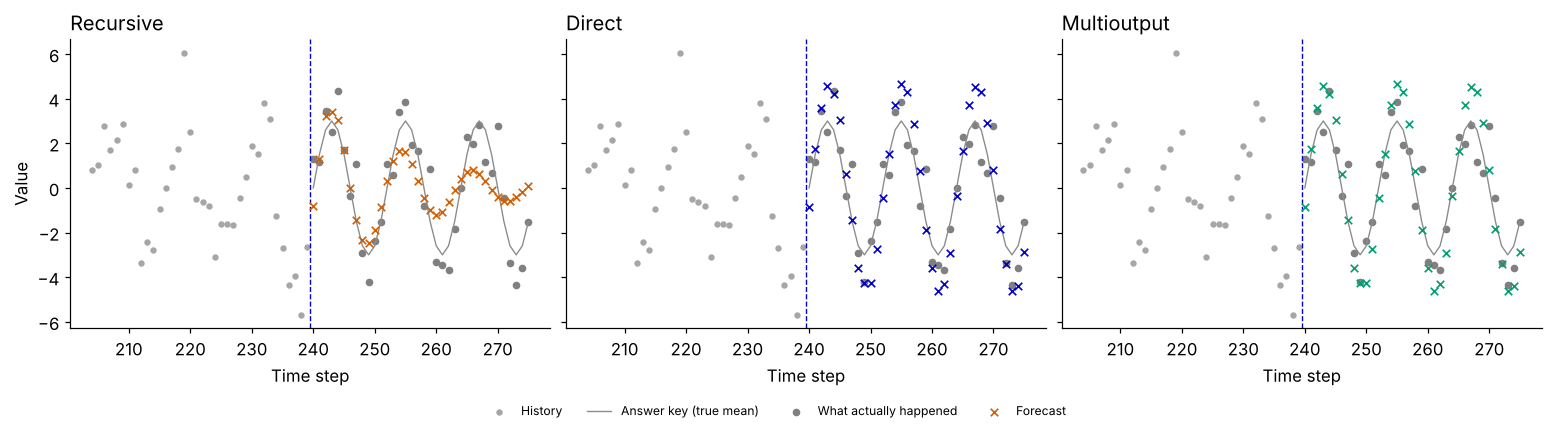

In [2]:
HORIZON, WINDOW = 36, 4
SEEDS = range(40)
seasonal = Scenario("seasonal", context_length=240, horizon=HORIZON,
                    parameters={"amplitude": 3., "period": 12., "sigma": 1.})


def scaled_ridge(reduction):
    return Pipeline(window_length=WINDOW, reduction=reduction).add(StandardScaler()).add(Ridge(alpha=1.))


runs = {reduction: scaled_ridge(reduction).run([seasonal], seeds=SEEDS) for reduction in REDUCTIONS}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True, constrained_layout=True)
for ax, (reduction, run) in zip(axes, runs.items()):
    entry = run.cases[0]
    history = entry.case.task.context.iloc[-36:]
    ax.scatter(history.index, history.iloc[:, 0], color="0.65", s=10, label="History")
    ax.plot(entry.case.reference.index, entry.case.reference.mean[:, 0], color="0.55", linewidth=.9,
            label="Answer key (true mean)")
    ax.scatter(entry.case.observed.index, entry.case.observed.iloc[:, 0], color="0.5", s=16,
               label="What actually happened")
    ax.scatter(entry.forecast.index, entry.forecast.point[:, 0], marker="x", color=COLORS[reduction], s=24,
               linewidths=1.1, label="Forecast", zorder=4)
    ax.axvline(entry.forecast.index[0] - .5, color="#0000CC", linestyle="--", linewidth=.9)
    ax.set(title=reduction.capitalize(), xlabel="Time step")
axes[0].set_ylabel("Value")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4, fontsize=8)
plt.show()

The recursive forecast starts well, then its swing shrinks with every cycle as its own predictions fill the window. The direct and multioutput forecasts keep the full swing, because each step ahead is learned from real windows of history, not from earlier forecasts. Direct and multioutput give the same forecast here; the next section says why.

## How much worse is recursive?

Each run comes with the usual TimeGym report, which scores every series. The main score is the error against the answer key (`mean_reference_mse`): how far the forecast is from the true mean. The error against what actually happened (`mse`) also includes noise nobody can predict. We also show the mean absolute error (`mae`).

In [3]:
scores = pd.DataFrame([{"reduction": reduction, "seed": result.seed,
                        "error against the answer key": result.metrics["mean_reference_mse"],
                        "error against what happened": result.metrics["mse"],
                        "mean absolute error": result.metrics["mae"]}
                       for reduction, run in runs.items() for result in run.report.cases])
display(scores.drop(columns="seed").groupby("reduction", sort=False).mean().round(3))

table = scores.pivot(index="seed", columns="reduction", values="error against the answer key")
np.testing.assert_allclose(table["direct"], table["multioutput"], rtol=1e-8)  # for Ridge, multioutput is direct
difference = table["direct"] - table["recursive"]
interval = paired_t_interval(difference)
assert interval["ci95"][1] < 0  # direct beats recursive across series
print(f"Direct minus recursive, error against the answer key: {interval['mean']:.2f} "
      f"(95% interval {interval['ci95'][0]:.2f} to {interval['ci95'][1]:.2f}). "
      f"Direct is lower on {(difference < 0).sum()} of {len(difference)} series.")

,error against the answer key,error against what happened,mean absolute error
reduction,,,
recursive,2.477,3.482,1.537
direct,0.556,1.578,1.006
multioutput,0.556,1.578,1.006


Direct minus recursive, error against the answer key: -1.92 (95% interval -2.15 to -1.70). Direct is lower on 39 of 40 series.


Direct and multioutput cut the error against the answer key from 2.48 to 0.56, by more than three quarters, and direct beats recursive on 39 of the 40 series. Direct and multioutput agree to rounding error: Ridge fits each output by the same penalized least squares on the same inputs, so fitting all 36 at once changes nothing.

A single score per series averages over all 36 steps, so it can't say where recursive falls behind.

## Where does recursive error build up?

For each step ahead, we average the squared distance between the forecast and the answer key over the 40 series. The bands are 95% intervals across series, for each step on its own.

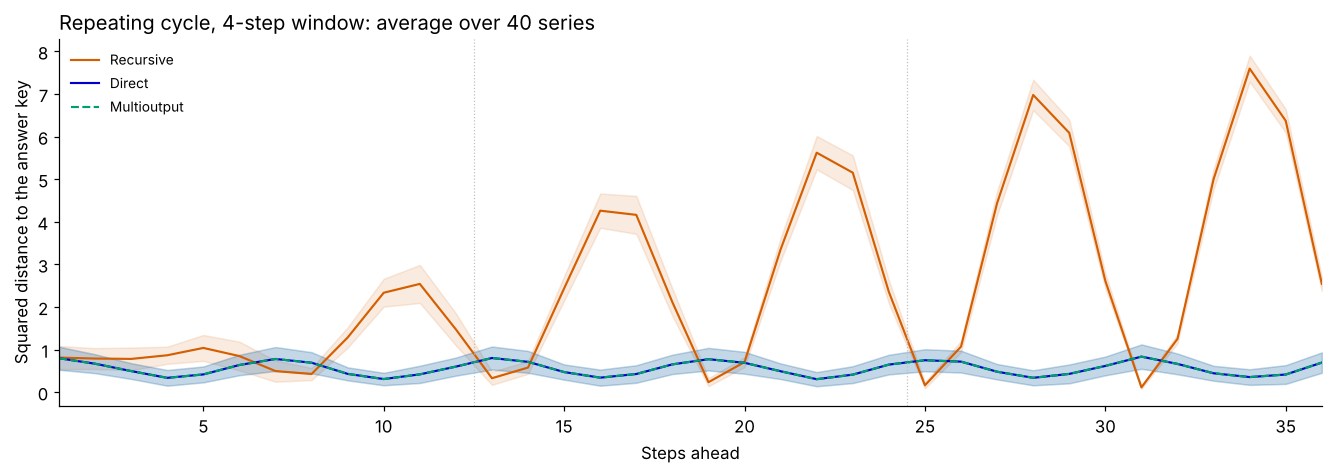

In [4]:
def plot_error_by_horizon(runs, title):
    fig, ax = plt.subplots(figsize=(12, 4.2), constrained_layout=True)
    horizons = np.arange(1, HORIZON + 1)
    for reduction, run in runs.items():
        errors = np.asarray([((entry.forecast.point - entry.case.reference.mean) ** 2)[:, 0]
                             for entry in run.cases])
        mean = errors.mean(axis=0)
        half = stats.t.ppf(.975, len(errors) - 1) * errors.std(axis=0, ddof=1) / np.sqrt(len(errors))
        style = "--" if reduction == "multioutput" else "-"
        ax.plot(horizons, mean, style, color=COLORS[reduction], linewidth=1.4, label=reduction.capitalize())
        ax.fill_between(horizons, mean - half, mean + half, color=COLORS[reduction], alpha=.12)
    for boundary in (12.5, 24.5):
        ax.axvline(boundary, color="0.75", linewidth=.8, linestyle=":")
    ax.set(xlabel="Steps ahead", ylabel="Squared distance to the answer key",
           xlim=(1, HORIZON), title=title)
    ax.legend(fontsize=9, loc="upper left")
    plt.show()


plot_error_by_horizon(runs, f"Repeating cycle, {WINDOW}-step window: average over {len(SEEDS)} series")

Recursive error rises and falls with the cycle, and each peak is higher than the last. Four past values are too few to pin down the cycle, so each one-step prediction is a little off, and the recursive model feeds that error into its next input: the error compounds. Direct and multioutput errors repeat the same small pattern every cycle, because no step depends on an earlier forecast. Dotted lines mark where each cycle ends.

## When the one-step model is right, nothing compounds

Compounding needs a one-step model that is wrong. So we repeat the comparison on mean reversion (AR(1)), where shocks fade: the latest value carries everything the next one depends on, so four lags are more than enough.

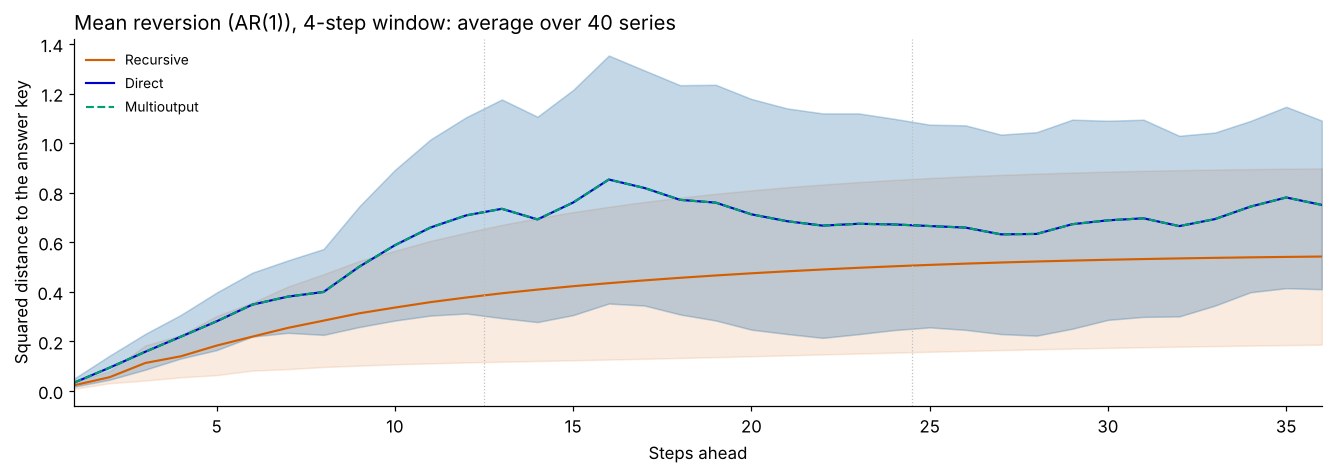

Direct minus recursive, error against the answer key: 0.194 (95% interval -0.086 to 0.474, 40 series)


In [5]:
ar1 = Scenario("ar1", context_length=240, horizon=HORIZON, parameters={"phi": .9, "sigma": 1.})
ar1_runs = {reduction: scaled_ridge(reduction).run([ar1], seeds=SEEDS) for reduction in REDUCTIONS}
plot_error_by_horizon(ar1_runs, f"Mean reversion (AR(1)), {WINDOW}-step window: average over {len(SEEDS)} series")
ar1_scores = pd.DataFrame({reduction: [result.metrics["mean_reference_mse"] for result in run.report.cases]
                           for reduction, run in ar1_runs.items()})
interval = paired_t_interval(ar1_scores["direct"] - ar1_scores["recursive"])
print(f"Direct minus recursive, error against the answer key: {interval['mean']:.3f} "
      f"(95% interval {interval['ci95'][0]:.3f} to {interval['ci95'][1]:.3f}, {interval['n']} series)")

Here the recursive error levels off as its forecast settles towards the mean: nothing compounds. Its average even stays below direct at every step. Recursive learns a single one-step relation from every window of the history. Each direct regressor learns its own longer-range relation, from fewer windows (its targets must fall inside the history) and from targets that get noisier the further ahead they are. With 40 series the bands overlap and the interval for the difference includes zero, so this shows that nothing compounds, not that recursive is better.

Compounding errors are a sign of a wrong one-step model, not of recursion itself.

## When multioutput differs from direct

Ridge can't tell multioutput from direct. A random forest can: a multioutput forest grows each tree to fit all 36 steps at once and shares its splits across them, while direct grows a separate forest for every step. Trees need no scaler. To keep the run short, this uses 20 of the 40 seasonal series.

In [6]:
forest = RandomForestRegressor(n_estimators=30, min_samples_leaf=5, random_state=0)
forest_runs = {reduction: Pipeline(forest, window_length=WINDOW, reduction=reduction)
               .run([seasonal], seeds=SEEDS[:20]) for reduction in REDUCTIONS}
forest_scores = pd.DataFrame({reduction: [result.metrics["mean_reference_mse"] for result in run.report.cases]
                              for reduction, run in forest_runs.items()})
display(forest_scores.mean().rename("error against the answer key").to_frame().T.round(3))
interval = paired_t_interval(forest_scores["multioutput"] - forest_scores["direct"])
assert interval["ci95"][1] < 0  # the shared forest beats the per-step forests
print(f"Multioutput minus direct: {interval['mean']:.3f} "
      f"(95% interval {interval['ci95'][0]:.3f} to {interval['ci95'][1]:.3f}, {interval['n']} series)")

,recursive,direct,multioutput
error against the answer key,0.752,0.457,0.347


Multioutput minus direct: -0.110 (95% interval -0.173 to -0.046, 20 series)


The forest repeats the recursive penalty, and here the shared multioutput forest is also more accurate than the per-step forests. For a model that can pool what it learns across steps, multioutput is a different model, not just a faster way to fit direct.

## Change one thing

- Set `WINDOW = 12`, a full cycle, and see whether the recursive error still compounds.
- Raise `sigma` in the seasonal scenario and watch the one-step fit, and the recursive error, get worse.
- Replace Ridge with `SVR()`. It can't fit several outputs at once, so the multioutput reduction wraps it in `MultiOutputRegressor` and matches direct again.
- Add a `target_transform` from [Target transforms](29_target_transforms.ipynb); the reduction and the transform are independent settings.

**What this doesn't show.** Two simulated processes, one window length and two kinds of regressor show the mechanism; they don't rank the reductions in general. The bands in the step-by-step plots hold for each step on its own, not for the whole curve at once. Reductions return point forecasts only, so this compares the center of the forecast, not its uncertainty.

Reading: [Ben Taieb et al. (2012)](https://doi.org/10.1016/j.eswa.2012.01.039).

**Next:** [Multivariate forecasting](21_multivariate_forecasting.ipynb).